<a href="https://colab.research.google.com/github/localzet/localzet/blob/main/education/dgtu/ml-creative-industries/lab03-wine-quality/Lab3_CRISPDM_Wine_Quality_MIK21.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## ДГТУ · Лабораторная работа № 3
# Анализ качества вина по CRISP-DM

**Дисциплина:** Проект — применение машинного обучения в креативных индустриях  
**Группа:** МИК21  
**Задание:** решить [Wine Quality](https://www.kaggle.com/datasets/rajyellow46/wine-quality) на основе методологии CRISP-DM.

**Этапы:** 1. Business Understanding → 2. Data Understanding → 3. Data Preparation → 4. Modeling → 5. Evaluation → 6. Deployment.

**Как выполнить:** откройте ноутбук в Google Colab и выберите «Среда выполнения → Выполнить все». Результаты строятся на реальных данных; значения метрик вычисляются при выполнении, а не прописаны заранее.

## 1. Business Understanding — понимание задачи

**Сценарий:** оценить качество вина по лабораторным измерениям для предварительного отбора образцов, которым требуется внимание дегустаторов. Алгоритм не заменяет экспертную оценку.

**Вход:** тип вина (красное/белое), 11 физико-химических показателей.  
**Выход:** экспертный балл качества (числовая шкала; постановка — регрессия).  
**Основная метрика:** MAE, средняя абсолютная ошибка в баллах. Дополнительные: RMSE и R².  
**Baseline:** прогноз среднего балла.  
**Проверяемая гипотеза:** одна из ML-моделей окажется лучше baseline по MAE на отложенном тесте; улучшение на 10% — учебный ориентир.

Регрессия выбрана потому, что цель — предсказать уровень экспертной оценки, а не отнести образец к произвольно выбранному бинарному классу.

In [1]:
import io
import hashlib
from pathlib import Path
from urllib.request import Request, urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
np.random.seed(SEED)
print("pandas:", pd.__version__, "scikit-learn:", sklearn.__version__)

pandas: 2.2.3 scikit-learn: 1.6.1


## 2. Data Understanding — понимание данных

**Data Card (паспорт данных)**

| Поле | Характеристика |
|---|---|
| Первоначальный источник | Cortez et al. (2009), UCI Wine Quality |
| Вариант для задания | Kaggle rajyellow46: winequalityN.csv, красные и белые вина |
| Объём | 6 497 наблюдений, 13 столбцов |
| Признаки | 11 числовых измерений и категориальный тип вина |
| Цель | quality — экспертный балл (набор допускает регрессию и классификацию) |
| Качество данных | проверить пропуски, повторы, редкие оценки и смещения |
| Ограничения | нет года, виноградника, производителя или дегустатора |
| Права | исходные данные UCI опубликованы с CC BY 4.0; атрибуция обязательна |

**Ссылки:** [Kaggle](https://www.kaggle.com/datasets/rajyellow46/wine-quality), [UCI](https://archive.ics.uci.edu/dataset/186/wine+quality), [DOI](https://doi.org/10.24432/C56S3T).

Для воспроизводимости используем общедоступную копию того же Kaggle CSV из GitHub и проверяем SHA-1 Git blob. При необходимости файл winequalityN.csv можно положить рядом с ноутбуком.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/Anushka298/Wine-quality-prediction/main/winequalityN.csv"
DATA_SHA1 = "669bbb1f2f781c0b94673d9174761fbc5c531e0f"

def git_blob_sha(data: bytes) -> str:
    return hashlib.sha1(f"blob {len(data)}\0".encode() + data).hexdigest()

local_file = next((p for p in [Path("winequalityN.csv"), Path("data/winequalityN.csv")] if p.exists()), None)
if local_file:
    content = local_file.read_bytes()
    print("Данные загружены локально:", local_file)
else:
    try:
        with urlopen(Request(DATA_URL, headers={"User-Agent": "Mozilla/5.0"}), timeout=30) as response:
            content = response.read()
    except Exception as exc:
        raise RuntimeError("Не удалось загрузить CSV: скачайте winequalityN.csv с Kaggle и поместите рядом с ноутбуком.") from exc

assert git_blob_sha(content) == DATA_SHA1, "Датасет отличается от зафиксированной версии"
df = pd.read_csv(io.BytesIO(content))
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_", regex=False)
assert len(df) == 6497
print("Размер данных:", df.shape)
display(df.head())

Размер данных: (6497, 13)


,type,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [3]:
num_cols = [c for c in df.columns if c not in ("type", "quality")]
feature_cols = ["type"] + num_cols
df["type"] = df["type"].str.strip().str.lower()
for c in num_cols + ["quality"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
print("Пропущенные значения по столбцам:")
display(df.isna().sum().rename("missing").to_frame().T)
print("Точные повторяющиеся строки:", int(df.duplicated().sum()))
print("Типы вина:")
display(df["type"].value_counts())
print("Распределение quality:")
display(df["quality"].value_counts().sort_index())
display(df.describe(include="all").T.round(3))

Пропущенные значения по столбцам:


,type,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality
missing,0,10,8,3,2,2,0,0,0,9,4,0,0


Точные повторяющиеся строки: 1168
Типы вина:


,count
type,
white,4898
red,1599


Распределение quality:


,count
quality,
3,30
4,216
5,2138
6,2836
7,1079
8,193
9,5


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
type,6497,2,white,4898,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fixed_acidity,6487.0,NaN,NaN,NaN,7.216579,1.29675,3.8,6.4,7.0,7.7,15.9
volatile_acidity,6489.0,NaN,NaN,NaN,0.339691,0.164649,0.08,0.23,0.29,0.4,1.58
citric_acid,6494.0,NaN,NaN,NaN,0.318722,0.145265,0.0,0.25,0.31,0.39,1.66
residual_sugar,6495.0,NaN,NaN,NaN,5.444326,4.758125,0.6,1.8,3.0,8.1,65.8
chlorides,6495.0,NaN,NaN,NaN,0.056042,0.035036,0.009,0.038,0.047,0.065,0.611
free_sulfur_dioxide,6497.0,NaN,NaN,NaN,30.525319,17.7494,1.0,17.0,29.0,41.0,289.0
total_sulfur_dioxide,6497.0,NaN,NaN,NaN,115.744574,56.521855,6.0,77.0,118.0,156.0,440.0
density,6497.0,NaN,NaN,NaN,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
ph,6488.0,NaN,NaN,NaN,3.218395,0.160748,2.72,3.11,3.21,3.32,4.01


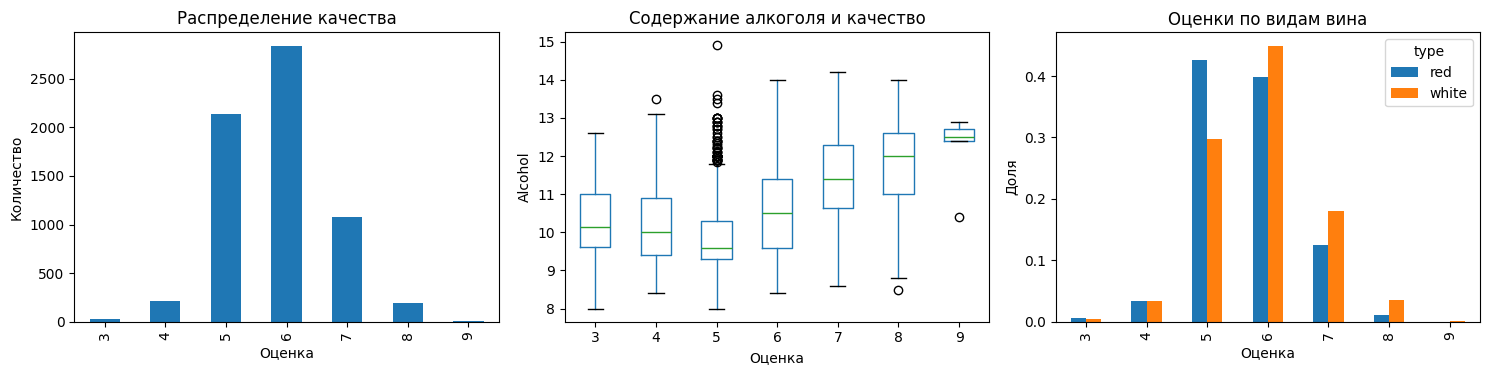

,quality
quality,1.000
alcohol,0.444
citric_acid,0.086
free_sulfur_dioxide,0.055
sulphates,0.039
ph,0.019
residual_sugar,-0.037
total_sulfur_dioxide,-0.041
fixed_acidity,-0.077
chlorides,-0.201


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df["quality"].value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set(title="Распределение качества", xlabel="Оценка", ylabel="Количество")
df.boxplot(column="alcohol", by="quality", ax=axes[1], grid=False)
axes[1].set(title="Содержание алкоголя и качество", xlabel="Оценка", ylabel="Alcohol")
df.groupby("type")["quality"].value_counts(normalize=True).unstack().T.plot.bar(ax=axes[2])
axes[2].set(title="Оценки по видам вина", xlabel="Оценка", ylabel="Доля")
plt.suptitle("")
plt.tight_layout()
plt.show()
display(df[num_cols + ["quality"]].corr(numeric_only=True)[["quality"]].sort_values("quality", ascending=False).round(3))

**Промежуточные выводы:** в исходном CSV — 6 497 образцов (4 898 белых и 1 599 красных), 38 пустых значений в числовых признаках и 1 168 полностью повторяющихся строк. Основная масса оценок относится к среднему качеству, крайние баллы встречаются редко.

**Ограничения:** одинаковые измерения без ID образца не обязательно являются ошибкой; для осторожной оценки повторные строки удаляются. Случайный train/test split может приводить к утечке совпадающих характеристик. Нет дат для временной проверки и нет доказательств причинного действия химических показателей.

## 3. Data Preparation — подготовка данных

Удаляем строки с неизвестным целевым значением и полностью одинаковые строки. Все записи с совпадающим набором **входных признаков** помещаем в одну группу (даже когда баллы различаются).

С помощью GroupShuffleSplit получаем приблизительно 60% train, 20% validation и 20% test. Медиа́ны пропусков, кодирование типа вина и масштабирование вычисляются **исключительно внутри Pipeline при обучении**, исключая утечку статистики из test.

In [5]:
data = df[df["type"].isin(["red", "white"])].dropna(subset=["quality"])
data = data.drop_duplicates().reset_index(drop=True)
X = data[feature_cols]
y = data["quality"].astype(float)

def group_hash(row):
    text = "|".join("<NA>" if pd.isna(v) else str(v) for v in row)
    return hashlib.sha1(text.encode()).hexdigest()

groups = X.apply(group_hash, axis=1)

split1 = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
dev_idx, test_idx = next(split1.split(X, y, groups=groups))
split2 = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
inner_train, inner_val = next(split2.split(X.iloc[dev_idx], y.iloc[dev_idx], groups=groups.iloc[dev_idx]))
train_idx, val_idx = dev_idx[inner_train], dev_idx[inner_val]

X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]
X_dev, y_dev = X.iloc[dev_idx], y.iloc[dev_idx]

a, b, c = (set(groups.iloc[i]) for i in (train_idx, val_idx, test_idx))
assert a.isdisjoint(b) and a.isdisjoint(c) and b.isdisjoint(c)
print("После очистки:", len(data))
print("train / val / test:", len(X_train), len(X_val), len(X_test))
print("Пересечений групп между выборками: 0")
display(pd.DataFrame({
    "train": y_train.value_counts(normalize=True),
    "val": y_val.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True)
}).fillna(0).sort_index().round(3))

После очистки: 5329
train / val / test: 3197 1066 1066
Пересечений групп между выборками: 0


,train,val,test
quality,,,
3.0,0.006,0.007,0.005
4.0,0.036,0.037,0.049
5.0,0.327,0.347,0.317
6.0,0.446,0.410,0.434
7.0,0.156,0.174,0.161
8.0,0.028,0.025,0.032
9.0,0.001,0.001,0.002


In [6]:
preprocess = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_cols),
    ("wine_type", OneHotEncoder(handle_unknown="ignore"), ["type"]),
], sparse_threshold=0.0)

def pipeline_for(estimator):
    return Pipeline([("prep", clone(preprocess)), ("regressor", clone(estimator))])

def metrics(y_true, y_pred):
    return dict(
        MAE=mean_absolute_error(y_true, y_pred),
        RMSE=float(np.sqrt(mean_squared_error(y_true, y_pred))),
        R2=r2_score(y_true, y_pred)
    )

## 4. Modeling — построение моделей

**Четыре подхода:** DummyRegressor (константный baseline), Ridge, Random Forest, HistGradientBoosting. Гиперпараметры фиксируются до рассмотрения тестовых результатов. Лучшая модель выбирается по наименьшей MAE **валидации**; test не участвует в выборе.

In [7]:
models = {
    "Dummy (baseline)": DummyRegressor(strategy="mean"),
    "Ridge": Ridge(alpha=10.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=120, max_depth=16, min_samples_leaf=3,
        random_state=SEED, n_jobs=-1
    ),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=160, max_leaf_nodes=15,
        learning_rate=0.06, l2_regularization=1.0, random_state=SEED
    ),
}

validation_rows = []
for name, model in models.items():
    fitted = pipeline_for(model).fit(X_train, y_train)
    pred = fitted.predict(X_val)
    validation_rows.append({"model": name, **metrics(y_val, pred)})

validation = pd.DataFrame(validation_rows).sort_values("MAE").reset_index(drop=True)
display(validation.round(4))
winner = validation.iloc[0]["model"]
print("Выбор по validation MAE:", winner)

,model,MAE,RMSE,R2
0,Random Forest,0.5421,0.7038,0.3733
1,HistGradientBoosting,0.5458,0.7084,0.3652
2,Ridge,0.5752,0.7404,0.3065
3,Dummy (baseline),0.7115,0.8892,-0.0001


Выбор по validation MAE: Random Forest


## 5. Evaluation — независимая оценка и анализ ошибок

Победитель переобучается на train+validation. Итоговая **test** используется один раз. Для корректного сравнения baseline обучается на том же наборе. Отдельно исследуем ошибки красных/белых вин и редких баллов; общий MAE не доказывает равное качество на всех сегментах.

In [8]:
final_model = pipeline_for(models[winner]).fit(X_dev, y_dev)
base_model = pipeline_for(models["Dummy (baseline)"]).fit(X_dev, y_dev)
y_pred = final_model.predict(X_test)
y_base = base_model.predict(X_test)

test_table = pd.DataFrame([
    {"model": "Dummy (baseline)", **metrics(y_test, y_base)},
    {"model": winner, **metrics(y_test, y_pred)}
]).drop_duplicates("model")
display(test_table.round(4))
baseline_mae = mean_absolute_error(y_test, y_base)
best_mae = mean_absolute_error(y_test, y_pred)
improvement = (baseline_mae - best_mae) / baseline_mae * 100
print(f"Изменение MAE относительно baseline: {improvement:+.2f}%")
print("Ориентир (улучшение >= 10%):", "достигнут" if improvement >= 10 else "не достигнут")

,model,MAE,RMSE,R2
0,Dummy (baseline),0.7127,0.9061,-0.0001
1,Random Forest,0.5421,0.7028,0.3984


Изменение MAE относительно baseline: +23.93%
Ориентир (улучшение >= 10%): достигнут


Ошибки по типу вина:


,count,mean,median
type,,,
red,274,0.524,0.417
white,792,0.548,0.453


Ошибки по истинной оценке:


,count,mean
true,,
3.0,5,2.159
4.0,52,1.336
5.0,338,0.474
6.0,463,0.375
7.0,172,0.641
8.0,34,1.442
9.0,2,2.195


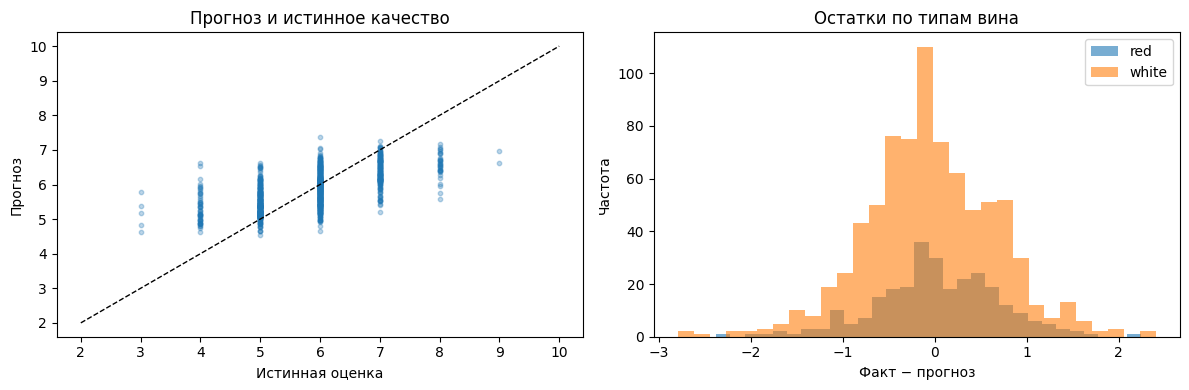

In [9]:
test_errors = pd.DataFrame({
    "type": X_test["type"].to_numpy(),
    "true": y_test.to_numpy(),
    "pred": y_pred,
})
test_errors["abs_error"] = (test_errors["true"] - test_errors["pred"]).abs()
test_errors["residual"] = test_errors["true"] - test_errors["pred"]
print("Ошибки по типу вина:")
display(test_errors.groupby("type")["abs_error"].agg(["count", "mean", "median"]).round(3))
print("Ошибки по истинной оценке:")
display(test_errors.groupby("true")["abs_error"].agg(["count", "mean"]).round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(test_errors["true"], test_errors["pred"], alpha=0.3, s=10)
ax[0].plot([2, 10], [2, 10], "k--", linewidth=1)
ax[0].set(title="Прогноз и истинное качество", xlabel="Истинная оценка", ylabel="Прогноз")
for kind, subset in test_errors.groupby("type"):
    ax[1].hist(subset["residual"], bins=30, alpha=0.6, label=kind)
ax[1].set(title="Остатки по типам вина", xlabel="Факт − прогноз", ylabel="Частота")
ax[1].legend()
plt.tight_layout()
plt.show()

,Ухудшение MAE при перемешивании
type,0.0000
density,0.0013
citric_acid,0.0034
total_sulfur_dioxide,0.0045
fixed_acidity,0.0055
chlorides,0.0122
residual_sugar,0.0131
ph,0.0132
sulphates,0.0135
volatile_acidity,0.0300


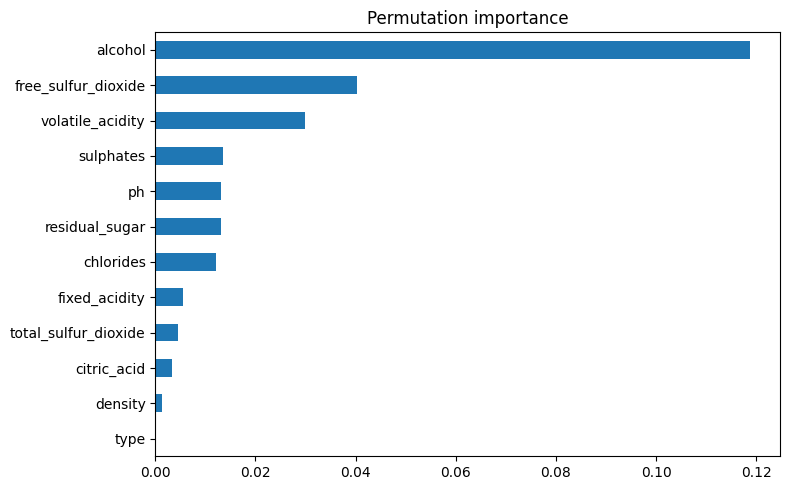

In [10]:
# Перемешивание одного признака: мера предсказательной важности (не причинности).
n = min(len(X_test), 300)
importance = permutation_importance(
    final_model, X_test.iloc[:n], y_test.iloc[:n],
    n_repeats=3, random_state=SEED, scoring="neg_mean_absolute_error"
)
imp = pd.Series(importance.importances_mean, index=feature_cols).sort_values()
display(imp.rename("Ухудшение MAE при перемешивании").to_frame().round(4))
imp.plot.barh(figsize=(8, 5))
plt.title("Permutation importance")
plt.tight_layout()
plt.show()

**Интерпретация:** на качестве могут сказываться ненаблюдаемые факторы — год сбора, происхождение, тип дегустации. Признаки могут быть коррелированы, а оценка субъективна. Permutation importance показывает ценность входа для данной модели на этой выборке, **не причинность**. Даже хороший test MAE не подтверждает переносимость на новые регионы или годы.

## 6. Deployment — демонстрация применения

Ниже модель предсказывает качество одного образца и сохраняется как локальный артефакт. Для реального продукта потребовались бы валидация входных полей, мониторинг качества, журнал версий и проверка новых партий. Вывод не используется для автоматического присвоения официальных оценок.

In [11]:
import joblib

sample = X_dev.iloc[[0]].copy()
estimated_quality = float(final_model.predict(sample)[0])
display(sample)
print(f"Пример прогноза: {estimated_quality:.2f} балла")
joblib.dump(final_model, "wine_quality_model.joblib")
print("Модель сохранена локально: wine_quality_model.joblib")

,type,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.001,3.0,0.45,8.8


Пример прогноза: 5.50 балла
Модель сохранена локально: wine_quality_model.joblib


## Итог и самопроверка

| Этап CRISP-DM | Что получено |
|---|---|
| Business Understanding | цель, критерий MAE, baseline, гипотеза |
| Data Understanding | паспорт источника, проверка схемы, пропусков, повторов, EDA |
| Data Preparation | групповое разбиение, импутация и кодирование внутри Pipeline |
| Modeling | несколько моделей и выбор по validation |
| Evaluation | test MAE/RMSE/R², сравнение baseline, сегментные ошибки |
| Deployment | пример прогноза и сохранение модели |

**Почему нельзя выбирать модель по test?** Тогда финальная оценка перестанет быть независимой.

**Почему нельзя считать отсутствие данных нулём?** Ноль может быть допустимым химическим измерением. Пропуски восстанавливаются медианами на обучающей части.

**Почему не хватает MAE в целом?** Ошибка на редких баллах и двух типах вина может существенно отличаться.

**Вывод формулируется по фактическому результату выполнения:** если улучшение относительно baseline не достигнуто, гипотеза не подтверждается; это нормальный результат исследовательской работы.

**Базовый источник:** Cortez, P. et al. (2009), Modeling wine preferences by data mining from physicochemical properties, Decision Support Systems; UCI Wine Quality, CC BY 4.0.